
# UNIVERSIDAD AUTÓNOMA DEL ESTADO DE MÉXICO

## Centro Universitario UAEM Zumpango

### Ingeniería en Computación

**Asignatura:** Investigación de Operaciones

**Actividad integradora:** Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook

## Práctica 1. Algoritmo de expansión mínima

**Método:** Algoritmo de Prim

**Integrantes:**
- Victor Alexis Diaz Morales
- David Israel Guerrero Estrada


**Docente:** Hazem Álvarez Rodriguez

**Fecha:** 19 Noviembre de 2026



## 1. Importación de bibliotecas

Para desarrollar esta práctica se utilizarán las bibliotecas NetworkX y Matplotlib.

NetworkX permitirá construir el grafo, identificar sus nodos y aristas, y trabajar con la estructura de la red.

Matplotlib permitirá representar gráficamente el grafo original y mostrar los cambios realizados durante cada iteración del algoritmo de Prim.


In [4]:

import networkx as nx
import matplotlib.pyplot as plt



## 2. Definición de los datos

Se establece una red de comunicación formada por ocho nodos, donde cada nodo representa un edificio universitario.

Las conexiones entre edificios se representan mediante aristas no dirigidas, debido a que la comunicación puede establecerse en ambos sentidos.

Cada arista tiene un peso que representa el costo hipotético de establecer la conexión.


In [5]:

# Definicion de los nodos

nodos = ["A", "B", "C", "D", "E", "F", "G", "H"]

# Definicion de las conexiones y sus pesos
aristas = [
    ("A", "B", 4),
    ("A", "C", 3),
    ("B", "C", 1),
    ("B", "D", 2),
    ("C", "D", 4),
    ("C", "E", 5),
    ("D", "E", 2),
    ("D", "F", 3),
    ("E", "F", 1),
    ("E", "G", 4),
    ("F", "G", 2),
    ("F", "H", 6),
    ("G", "H", 3),
    ("E", "H", 7)
]

# Crear el grafo
G = nx.Graph()

# Agregar los nodos
G.add_nodes_from(nodos)

# Agregar las aristas con sus pesos
G.add_weighted_edges_from(aristas)

print("Nodos:", G.nodes())
print("Cantidad de nodos:", G.number_of_nodes())
print("Cantidad de aristas:", G.number_of_edges())


Nodos: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Cantidad de nodos: 8
Cantidad de aristas: 14



## 3. Representación del grafo original

Se realiza la representación gráfica de la red para identificar los nodos, las conexiones existentes y los pesos asignados a cada arista.

Esta representación permite observar la estructura inicial del problema antes de aplicar el algoritmo de Prim.


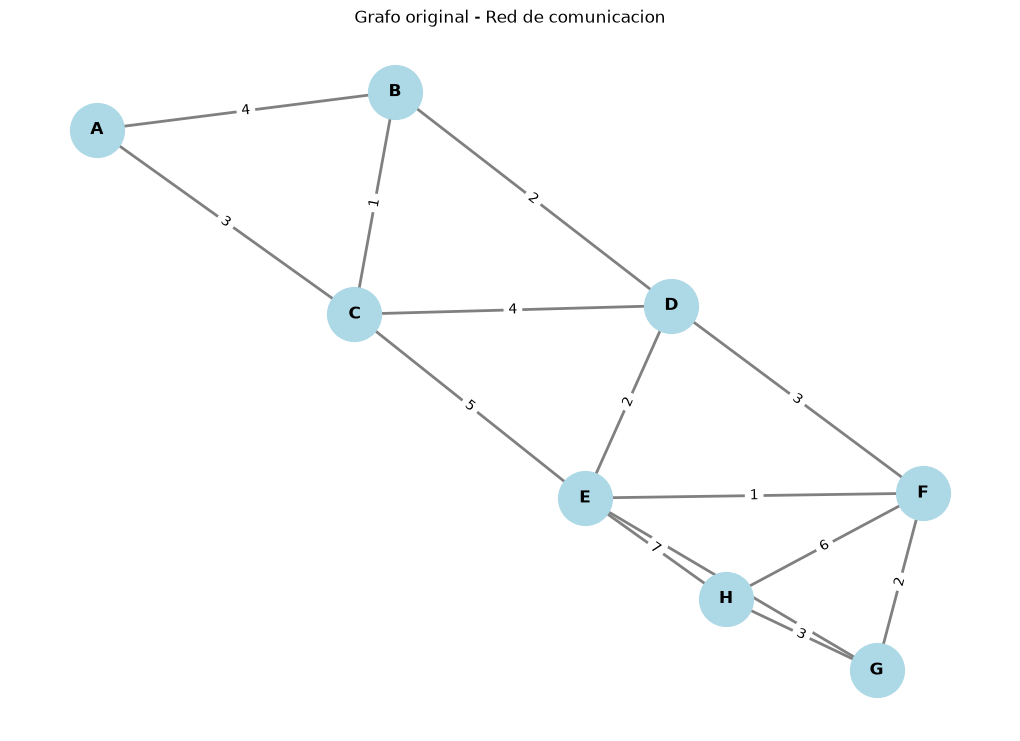

In [6]:

# Definir posiciones de los nodos
posiciones = nx.spring_layout(G, seed=42)

# Dibujar el grafo original
plt.figure(figsize=(10, 7))

nx.draw(
    G,
    posiciones,
    with_labels=True,
    node_color="lightblue",
    node_size=1500,
    font_size=12,
    font_weight="bold",
    edge_color="gray",
    width=2
)

# Mostrar los pesos de las aristas
pesos = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    posiciones,
    edge_labels=pesos,
    font_size=10
)

plt.title("Grafo original - Red de comunicacion")
plt.axis("off")
plt.show()



## 4. Desarrollo paso a paso del algoritmo de Prim

Para visualizar el procedimiento se creará una función que permita representar el grafo durante cada iteración.

Los nodos visitados se mostrarán en color verde, mientras que los nodos pendientes permanecerán en color azul.

Las aristas seleccionadas para construir el árbol de expansión mínima se mostrarán en color rojo.


In [7]:

def dibujar_paso(G, posiciones, nodos_visitados, aristas_seleccionadas, titulo):

    colores_nodos = []

    for nodo in G.nodes():
        if nodo in nodos_visitados:
            colores_nodos.append("lightgreen")
        else:
            colores_nodos.append("lightblue")

    plt.figure(figsize=(10, 7))

    nx.draw(
        G,
        posiciones,
        with_labels=True,
        node_color=colores_nodos,
        node_size=1500,
        font_size=12,
        font_weight="bold",
        edge_color="gray",
        width=1.5
    )

    # Resaltar las aristas seleccionadas
    if aristas_seleccionadas:
        nx.draw_networkx_edges(
            G,
            posiciones,
            edgelist=aristas_seleccionadas,
            edge_color="red",
            width=3
        )

    # Mostrar los pesos
    pesos = nx.get_edge_attributes(G, "weight")

    nx.draw_networkx_edge_labels(
        G,
        posiciones,
        edge_labels=pesos,
        font_size=10
    )

    plt.title(titulo)
    plt.axis("off")
    plt.show()



### Iteración inicial

Se selecciona el nodo A como punto de partida.

En este momento no se ha seleccionado ninguna arista. El árbol comienza únicamente con el nodo inicial.


Nodo inicial: A
Nodos visitados: ['A']
Aristas seleccionadas: []


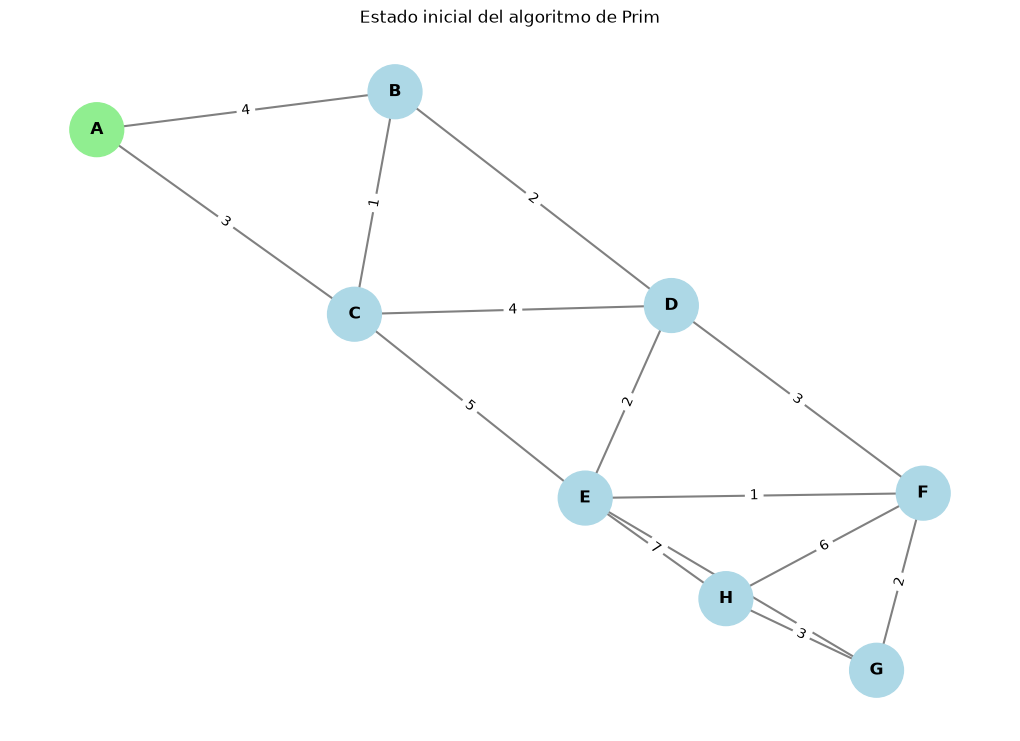

In [8]:

# Seleccionar el nodo inicial
nodo_inicial = "A"

# Lista de nodos visitados
nodos_visitados = [nodo_inicial]

# Lista de aristas seleccionadas
aristas_seleccionadas = []

print("Nodo inicial:", nodo_inicial)
print("Nodos visitados:", nodos_visitados)
print("Aristas seleccionadas:", aristas_seleccionadas)

dibujar_paso(
    G,
    posiciones,
    nodos_visitados,
    aristas_seleccionadas,
    "Estado inicial del algoritmo de Prim"
)


Conexiones disponibles:
A - C Peso: 3
A - B Peso: 4

Arista seleccionada: A - C
Peso: 3


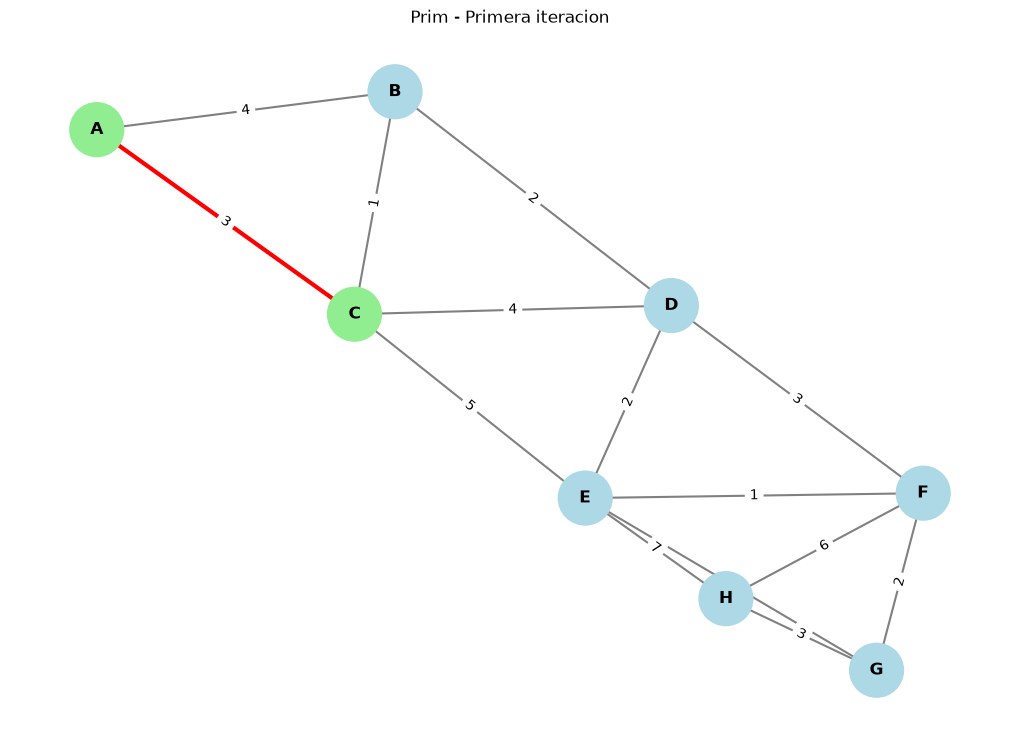

In [9]:

# Buscar las conexiones disponibles
conexiones_disponibles = []

for origen in nodos_visitados:
    for vecino in G.neighbors(origen):

        if vecino not in nodos_visitados:

            peso = G[origen][vecino]["weight"]

            conexiones_disponibles.append(
                (origen, vecino, peso)
            )

# Ordenar por peso
conexiones_disponibles.sort(key=lambda x: x[2])

print("Conexiones disponibles:")

for origen, destino, peso in conexiones_disponibles:
    print(origen, "-", destino, "Peso:", peso)

# Seleccionar la conexion menor
origen, destino, peso = conexiones_disponibles[0]

aristas_seleccionadas.append((origen, destino))
nodos_visitados.append(destino)

print("\nArista seleccionada:", origen, "-", destino)
print("Peso:", peso)

dibujar_paso(
    G,
    posiciones,
    nodos_visitados,
    aristas_seleccionadas,
    "Prim - Primera iteracion"
)


Conexiones disponibles:
C - B Peso: 1
A - B Peso: 4
C - D Peso: 4
C - E Peso: 5

Arista seleccionada: C - B
Peso: 1


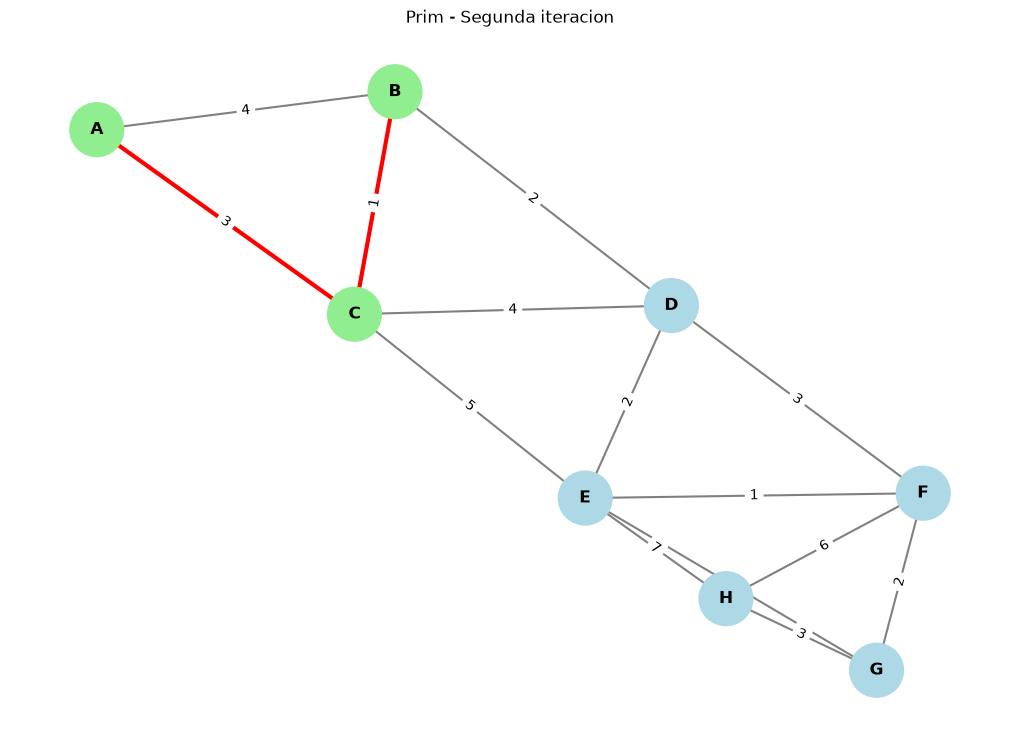

In [10]:

conexiones_disponibles = []

for origen in nodos_visitados:
    for vecino in G.neighbors(origen):

        if vecino not in nodos_visitados:

            peso = G[origen][vecino]["weight"]

            conexiones_disponibles.append(
                (origen, vecino, peso)
            )

conexiones_disponibles.sort(key=lambda x: x[2])

print("Conexiones disponibles:")

for origen, destino, peso in conexiones_disponibles:
    print(origen, "-", destino, "Peso:", peso)

origen, destino, peso = conexiones_disponibles[0]

aristas_seleccionadas.append((origen, destino))
nodos_visitados.append(destino)

print("\nArista seleccionada:", origen, "-", destino)
print("Peso:", peso)

dibujar_paso(
    G,
    posiciones,
    nodos_visitados,
    aristas_seleccionadas,
    "Prim - Segunda iteracion"
)


## Completar las iteraciones restantes
Para no repetir manualmente el mismo código siete veces, ahora utilizaremos un ciclo while, este realiza las mismas operaciones que en la iteracion anterior

Conexiones disponibles:
B - D Peso: 2
C - D Peso: 4
C - E Peso: 5

Arista seleccionada: B - D
Peso: 2
Nodos visitados: ['A', 'C', 'B', 'D']


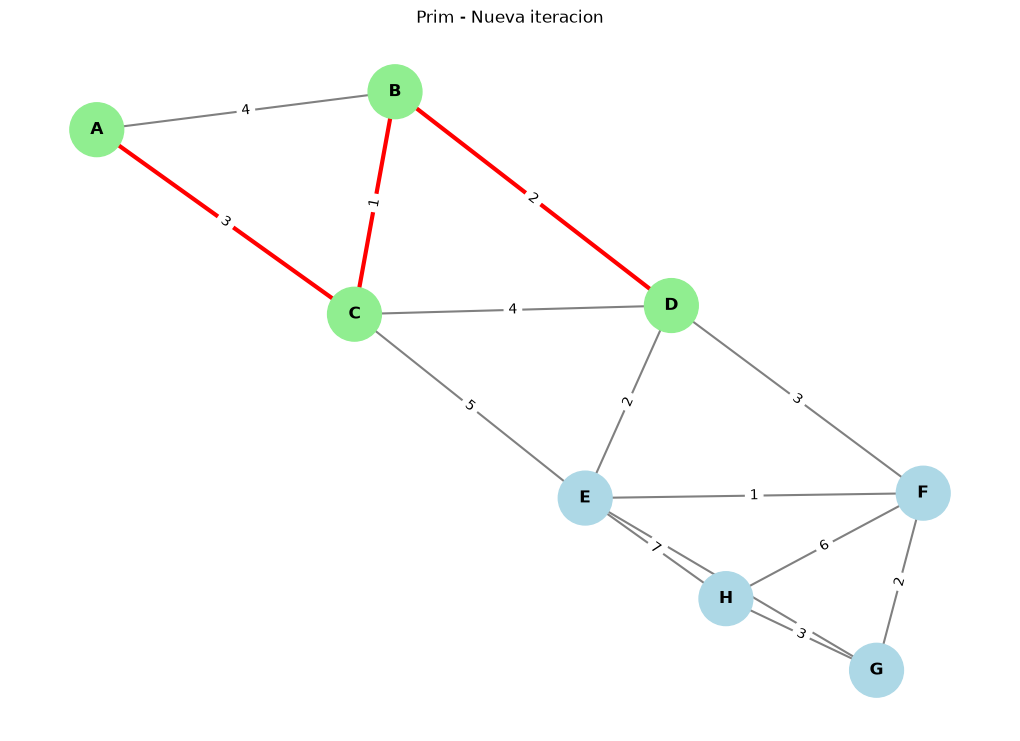

Conexiones disponibles:
D - E Peso: 2
D - F Peso: 3
C - E Peso: 5

Arista seleccionada: D - E
Peso: 2
Nodos visitados: ['A', 'C', 'B', 'D', 'E']


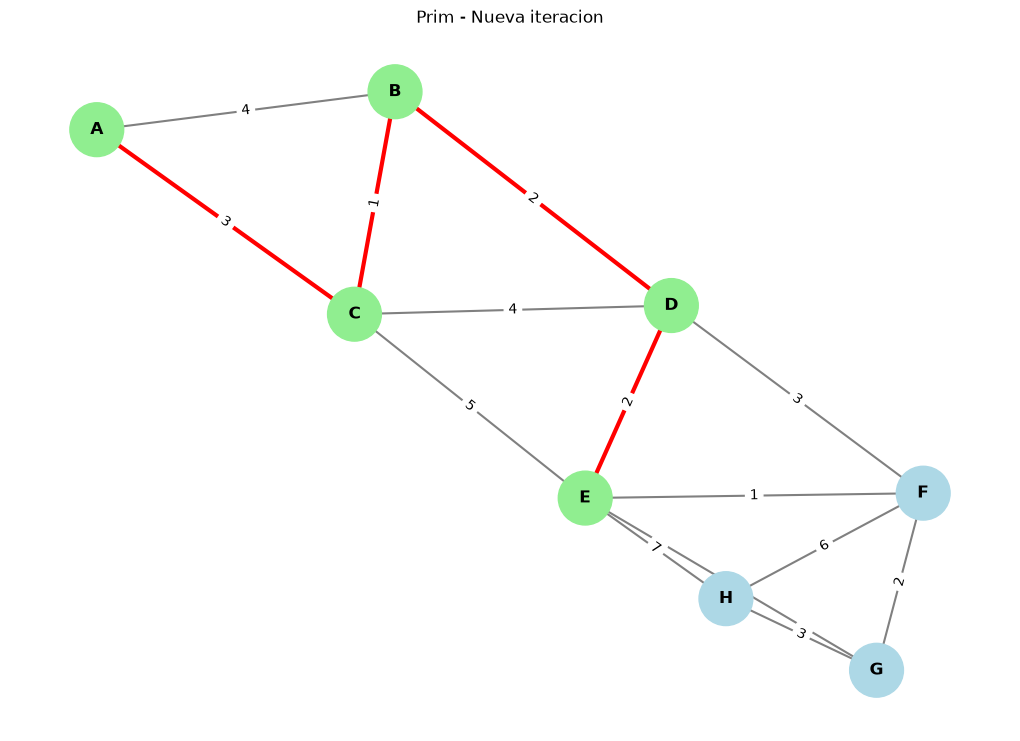

Conexiones disponibles:
E - F Peso: 1
D - F Peso: 3
E - G Peso: 4
E - H Peso: 7

Arista seleccionada: E - F
Peso: 1
Nodos visitados: ['A', 'C', 'B', 'D', 'E', 'F']


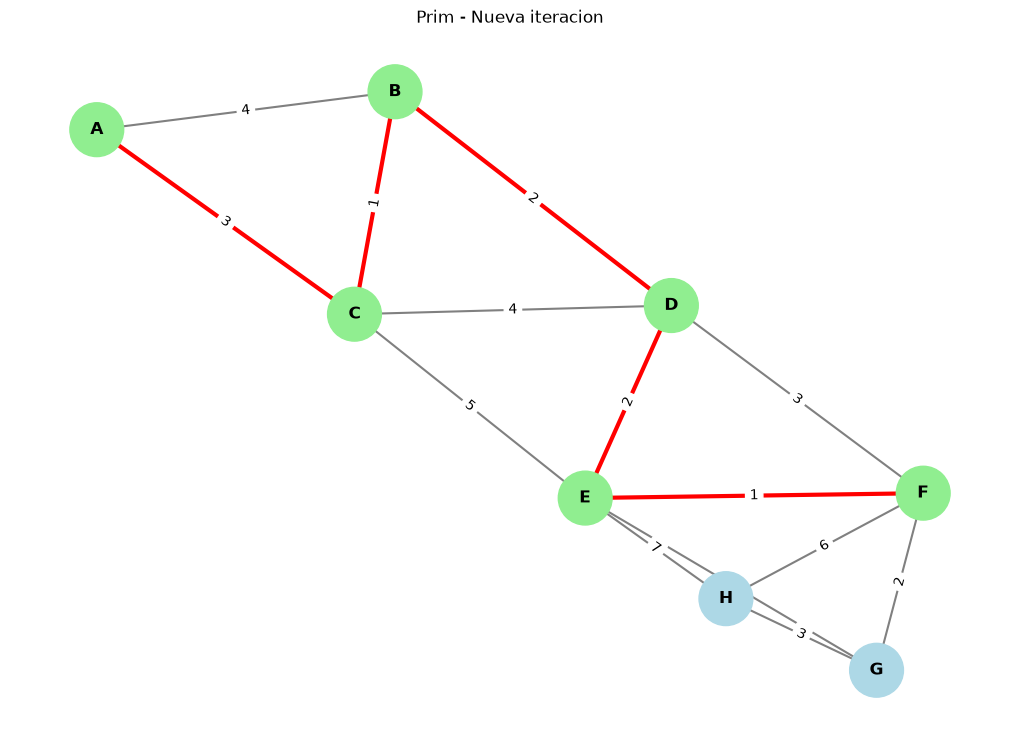

Conexiones disponibles:
F - G Peso: 2
E - G Peso: 4
F - H Peso: 6
E - H Peso: 7

Arista seleccionada: F - G
Peso: 2
Nodos visitados: ['A', 'C', 'B', 'D', 'E', 'F', 'G']


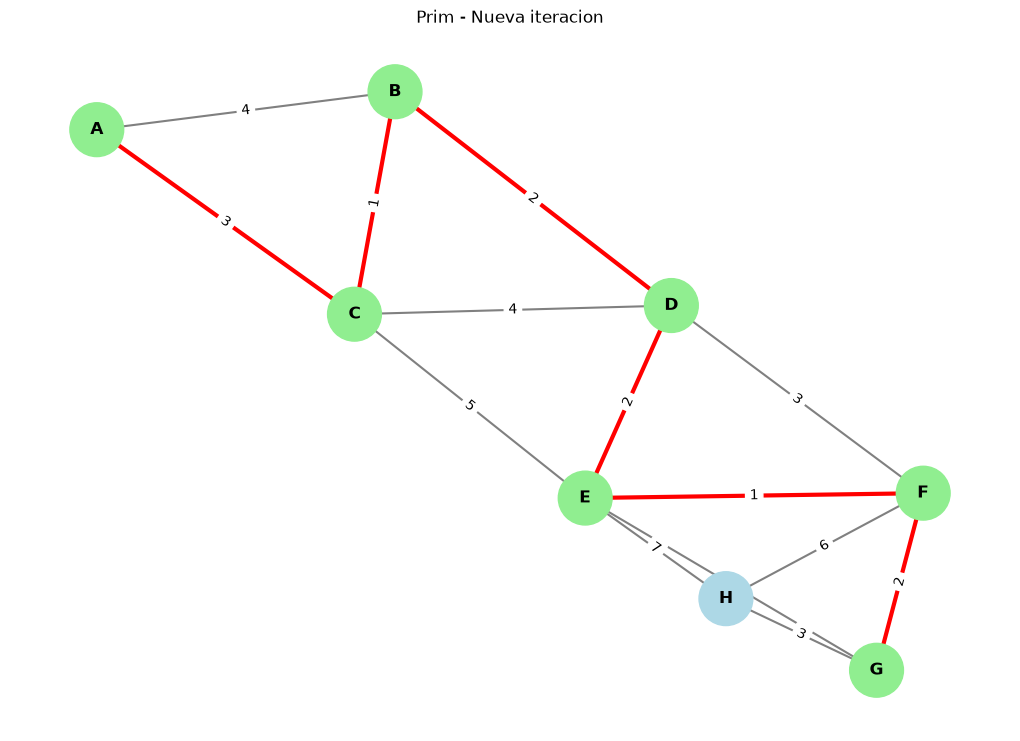

Conexiones disponibles:
G - H Peso: 3
F - H Peso: 6
E - H Peso: 7

Arista seleccionada: G - H
Peso: 3
Nodos visitados: ['A', 'C', 'B', 'D', 'E', 'F', 'G', 'H']


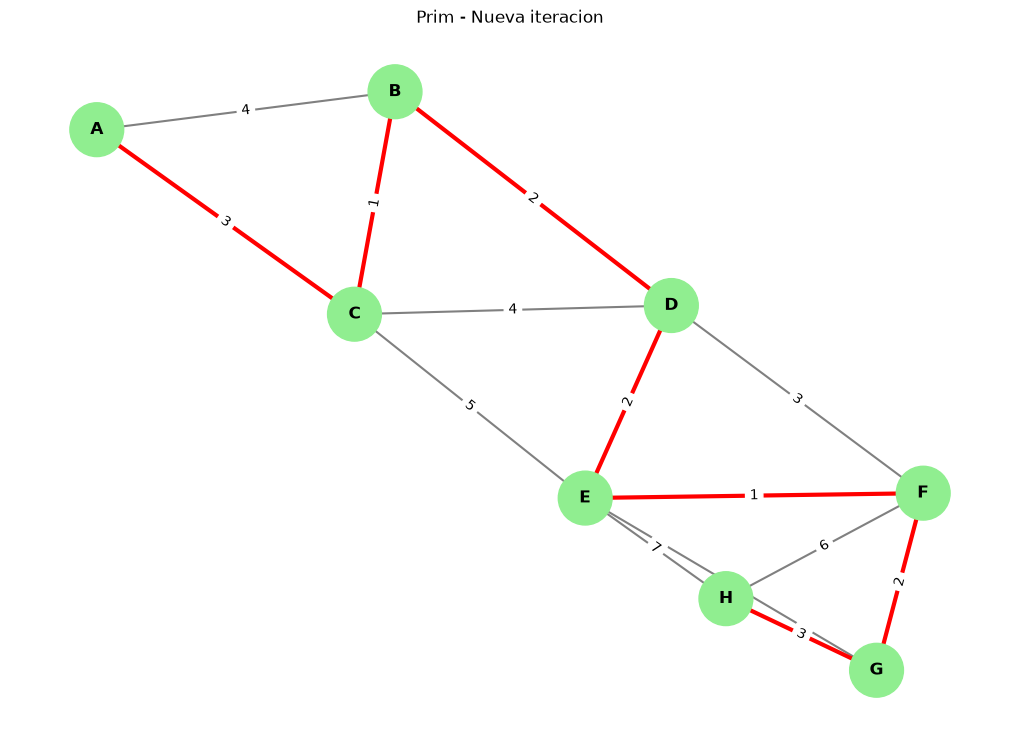

In [11]:

# Continuar mientras existan nodos sin visitar
while len(nodos_visitados) < len(nodos):

    conexiones_disponibles = []

    # Buscar conexiones entre nodos visitados y no visitados
    for origen in nodos_visitados:

        for vecino in G.neighbors(origen):

            if vecino not in nodos_visitados:

                peso = G[origen][vecino]["weight"]

                conexiones_disponibles.append(
                    (origen, vecino, peso)
                )

    # Ordenar las conexiones por peso
    conexiones_disponibles.sort(key=lambda x: x[2])

    print("Conexiones disponibles:")

    for origen, destino, peso in conexiones_disponibles:
        print(origen, "-", destino, "Peso:", peso)

    # Seleccionar la conexion de menor peso
    origen, destino, peso = conexiones_disponibles[0]

    aristas_seleccionadas.append((origen, destino))
    nodos_visitados.append(destino)

    print("\nArista seleccionada:", origen, "-", destino)
    print("Peso:", peso)
    print("Nodos visitados:", nodos_visitados)

    # Mostrar el estado actual del grafo
    dibujar_paso(
        G,
        posiciones,
        nodos_visitados,
        aristas_seleccionadas,
        "Prim - Nueva iteracion"
    )



## 5. Resultados del árbol de expansión mínima

Después de completar todas las iteraciones del algoritmo de Prim, se obtiene un conjunto de conexiones que permite comunicar todos los edificios utilizando el menor costo posible.

Se muestran las aristas seleccionadas, sus respectivos pesos y el costo total de la red.


In [12]:

# Calcular el costo total
costo_total = 0

print("ARBOL DE EXPANSION MINIMA\n")

for origen, destino in aristas_seleccionadas:

    peso = G[origen][destino]["weight"]

    print(origen, "-", destino, "Peso:", peso)

    costo_total += peso

print("\nCantidad de nodos:", len(nodos_visitados))
print("Cantidad de aristas:", len(aristas_seleccionadas))
print("Costo minimo total:", costo_total)


ARBOL DE EXPANSION MINIMA

A - C Peso: 3
C - B Peso: 1
B - D Peso: 2
D - E Peso: 2
E - F Peso: 1
F - G Peso: 2
G - H Peso: 3

Cantidad de nodos: 8
Cantidad de aristas: 7
Costo minimo total: 14



## 6. Representación del árbol de expansión mínima

Se realiza la representación gráfica de la solución obtenida mediante el algoritmo de Prim.

Se resaltan las siete aristas seleccionadas, permitiendo observar cómo quedan conectados todos los nodos de la red.


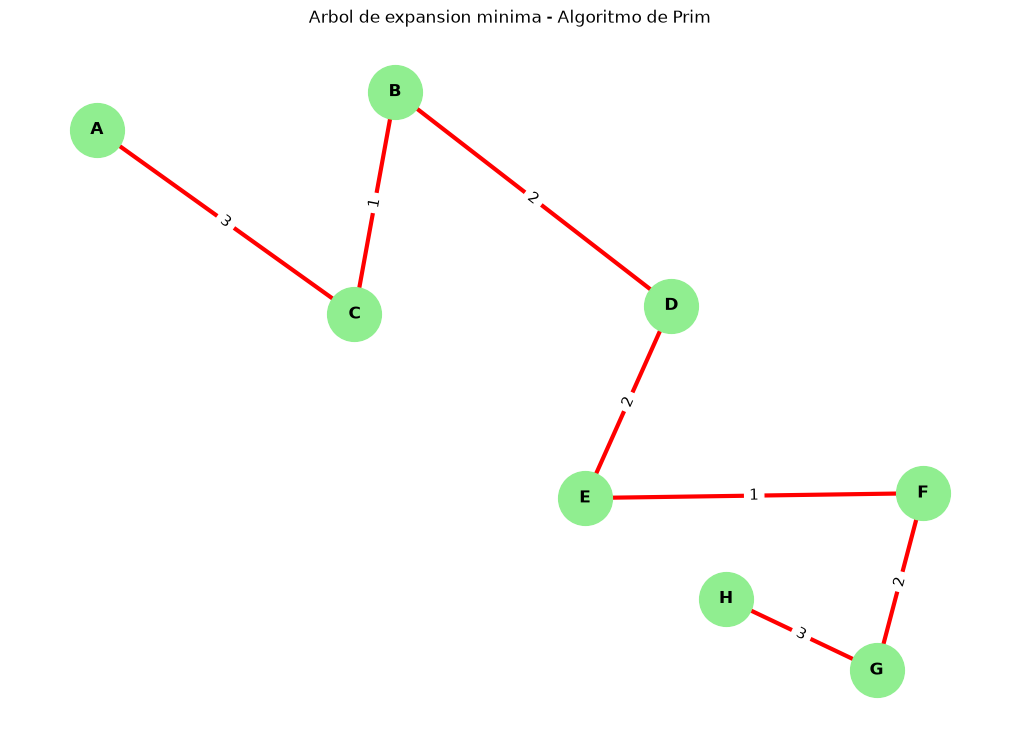

In [13]:

# Crear un nuevo grafo para representar la solucion
arbol_minimo = nx.Graph()

# Agregar los nodos
arbol_minimo.add_nodes_from(nodos)

# Agregar las aristas seleccionadas
for origen, destino in aristas_seleccionadas:

    peso = G[origen][destino]["weight"]

    arbol_minimo.add_edge(
        origen,
        destino,
        weight=peso
    )

# Dibujar el arbol final
plt.figure(figsize=(10, 7))

nx.draw(
    arbol_minimo,
    posiciones,
    with_labels=True,
    node_color="lightgreen",
    node_size=1500,
    font_size=12,
    font_weight="bold",
    edge_color="red",
    width=3
)

pesos_arbol = nx.get_edge_attributes(
    arbol_minimo,
    "weight"
)

nx.draw_networkx_edge_labels(
    arbol_minimo,
    posiciones,
    edge_labels=pesos_arbol,
    font_size=11
)

plt.title("Arbol de expansion minima - Algoritmo de Prim")
plt.axis("off")
plt.show()



## 7. Interpretación de resultados

Mediante la aplicación del algoritmo de Prim se obtuvo un árbol de expansión mínima compuesto por ocho nodos y siete aristas.

El costo total de las conexiones seleccionadas es de 14 unidades.

La solución permite conectar todos los edificios de la red sin generar ciclos y utilizando el menor costo posible de acuerdo con los pesos establecidos inicialmente.

Se observa que el algoritmo selecciona progresivamente las conexiones de menor peso disponibles, incorporando nuevos nodos hasta completar la red.

En el contexto de las tecnologías de la información, este procedimiento puede utilizarse como referencia para diseñar redes de comunicación, establecer conexiones entre equipos y optimizar los recursos necesarios para interconectar diferentes instalaciones.



## 8. Conclusión Victor

Durante el desarrollo de la práctica comprendí la importancia de utilizar herramientas computacionales para resolver problemas de investigación de operaciones. Python y sus bibliotecas permiten representar situaciones mediante grafos, realizar cálculos y visualizar los resultados de una manera más sencilla. Además, trabajar paso a paso me ayudó a comprender mejor el procedimiento y la utilidad del algoritmo.



## 9. Conclusión David

La realización de esta práctica me permitió reforzar mis conocimientos sobre la resolución de problemas mediante métodos matemáticos y programación. También comprendí que no basta con obtener un resultado, sino que es importante analizarlo e interpretar lo que representa dentro del problema planteado. El uso de Jupyter Notebook facilitó la ejecución del código y la presentación de los resultados de forma ordenada.


## 10. Conclusión general del equipo

Durante el desarrollo de esta práctica se comprendió el funcionamiento del algoritmo de Prim y su aplicación para encontrar un árbol de expansión mínima.

La implementación en Python permitió observar cómo se seleccionan las conexiones de menor peso y cómo se construye progresivamente una red que conecta todos los nodos sin generar ciclos.

La representación gráfica de cada iteración facilitó la comprensión del procedimiento, permitiendo identificar los nodos visitados y las aristas que forman parte de la solución.

Finalmente, se identificó la utilidad de los modelos de optimización de redes en el área de Ingeniería en Computación, especialmente en el diseño y planificación de infraestructuras de comunicación.
